### Общая нумерация: **задача 8** (модификация детектора на расположение детекторов по сфере большого радиуса)

In [1]:
from dataclasses import dataclass
import numpy as np

In [2]:
import matplotlib.pyplot as plt

def uniform_points_on_sphere(R=2, N=40):
    cos_theta = np.random.default_rng().uniform(-1, 1, N)
    sin_theta = np.sqrt(1-cos_theta**2)
    phi = np.random.default_rng().uniform(0, 2*np.pi, N)
    return R*np.array([np.cos(phi)*sin_theta, np.sin(phi)*sin_theta, cos_theta])

def plot_points_3d(points, *args):
    fig = plt.figure(figsize=plt.figaspect(0.5))
    ax = fig.add_subplot(1, 1, 1, projection='3d')
    ax.scatter(points[:,0], points[:, 1], points[:, 2])
    ax.view_init(*args)

#### Расположение детекторов на сфере по Фибоначчи, чтобы было достаточно равномерно для любого числа детекторов
#### Алгоритм определения попадания фотона на фотоумножитель изначально реализован на numpy без итераций по фотонам или по детекторам (`def points_are_in_pm`)

In [20]:
@dataclass
class Detector():
    R: float = 2. # m
    """Big Sphere Radius"""
    N: int = 40 
    """Amount of PMs"""
    r: float = 0.1 # m
    """PM Radius""" 
    a: float = 0.5
    """Photon Detection Efficiency"""
    position: tuple = (0., 0., 0.)
    """Sphere Center"""

    def __post_init__(self):
        # random_positions = uniform_points_on_sphere(self.R, self.N)
        self.place_pm_on_sphere()
        self.geometry = np.vstack((np.arange(1, self.geometry.shape[1]+1, 1), self.geometry)).T # add N_channel is in [1, N] 
        if isinstance(self.position, tuple): self.position = np.asarray(self.position)
        self.geometry[:, 1:] += self.position


    def place_pm_on_sphere(self) -> None:
        """Create points on sphere with Fibonachi"""
        N = self.N
        R = self.R
        i = np.arange(N, dtype=float)
        z = 1 - (2 * i + 1) / N
        r = np.sqrt(1.0 - z**2)
        golden_angle = np.pi * (3.0 - np.sqrt(5.0))
        theta = i * golden_angle
        x = R * r * np.cos(theta)
        y = R * r * np.sin(theta)
        z = R * z
        self.geometry = np.array([x, y, z])

    def point_is_in_pm(self, point) -> int:
        """Returns OM_ID of worked OM (is for 1 input point)"""
        # check if point is on sphere
        if not np.isclose(np.linalg.norm(point), self.R): 
            print("Point is not on shere")
            return 0 # N_channel=0 means point is not in any channel
        pm_pos = self.geometry[:, 1:]
        distances = np.linalg.norm(pm_pos - point, axis=1)
        # check if there is any point in area of channel
        mask = distances < self.r
        return self.geometry[mask, 0] # return om_id of worked om
    
    def points_are_in_pm(self, points: np.ndarray, traveled_paths: np.ndarray = None) -> np.ndarray:
        """Returns [OM_ID, weighted_counts] of worked OM
           weight is absorption weight with absorption length 8 m
           (is for array of points)
        """
        points = np.asarray(points)
        # take points on sphere
        mask_on_sphere = np.isclose(np.linalg.norm(points, axis=1), self.R)
        points_on_sphere = points[mask_on_sphere] 
        if points_on_sphere.size == 0: 
            print("No points on sphere")
            return np.empty((0, 2), dtype=np.int32)  # N_channel=0 means point is not in any channel
        pm_pos = self.geometry[:, 1:]
        distances = np.linalg.norm(pm_pos[:, None, :]  - points_on_sphere[None, :, :], axis=2)
        mask = distances < self.r
        pm_idx, pt_idx = np.where(mask)
        hitted_pms = self.geometry[pm_idx, 0]
        if traveled_paths is None:
            return np.vstack(np.unique(hitted_pms, return_counts=True)).astype(np.int32).T # [om_id, n_photons in it]
        
        traveled_paths = np.asarray(traveled_paths).ravel()
        if traveled_paths.size != points.shape[0]: 
            raise ValueError(f"Amount of traveled paths is not equal to amount of intersection points: {traveled_paths.size} != {points.shape[0]}")
        traveled_paths = traveled_paths[mask_on_sphere]
        traveled_paths = traveled_paths[pt_idx]
        absorption_weights = np.exp(-traveled_paths / 8)
        unique_pms, inverse_indices = np.unique(hitted_pms, return_inverse=True)
        weighted_counts = np.zeros(len(unique_pms), dtype=np.float32)
        np.add.at(weighted_counts, inverse_indices, absorption_weights) # sum weights corresponding to OM
        hits = np.vstack([unique_pms, weighted_counts]).T         
        return hits # [om_id, expected_photons]
    
    def make_charge(self, hits):
        hits[:, 1] = np.random.default_rng().poisson(self.a * hits[:, 1])
        return hits

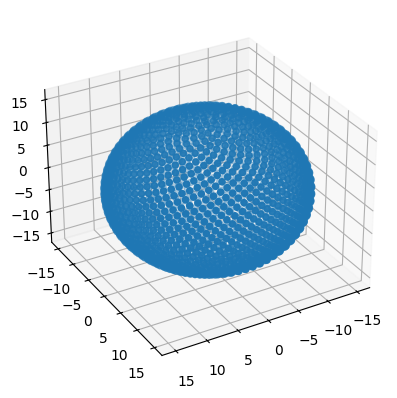

In [5]:
det = Detector(N=2000, R=15, position=(0, 0, 0))
plot_points_3d(det.geometry[:, 1:], 30, 60)

In [7]:
def test_points_are_in_pm():
    det = Detector(N=2000, R=15)
    pm_worked = det.points_are_in_pm([[0,0,0], det.geometry[0, 1:], [0,0,2], *det.geometry[:, 1:]]) 
    assert pm_worked.shape == (det.geometry.shape[0], 2)
    assert pm_worked[0, 1] == 2
    assert pm_worked[1:, 1].all() == 1
test_points_are_in_pm()